# Smart Beta and Factor Investing

FINM 36700 HW6: Smart-Beta

Group: Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

In [49]:
import pandas as pd
import numpy as np 
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


FILE = "factor_pricing_data.xlsx"

In [50]:
factors = pd.read_excel(FILE, sheet_name="factors (excess returns)", index_col="Date", parse_dates=True)
ports   = pd.read_excel(FILE, sheet_name="portfolios (excess returns)", index_col="Date", parse_dates=True)
ports.columns = ports.columns.str.strip()   

factors.head()

,MKT,SMB,HML,RMW,CMA,UMD
Date,,,,,,
1980-01-31,0.0550,0.0188,0.0185,-0.0184,0.0189,0.0745
1980-02-29,-0.0123,-0.0162,0.0059,-0.0095,0.0292,0.0789
1980-03-31,-0.1289,-0.0697,-0.0096,0.0182,-0.0105,-0.0958
1980-04-30,0.0396,0.0105,0.0103,-0.0218,0.0034,-0.0048
1980-05-31,0.0526,0.0200,0.0038,0.0043,-0.0063,-0.0118


In [51]:
ports.head()

,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1980-01-31,-0.0073,0.0285,0.0084,0.1009,-0.0143,0.0995,0.0348,0.0323,0.0048,0.0059,...,0.0158,0.0851,0.0466,-0.0125,0.0430,-0.0284,0.0254,0.0770,0.0306,0.0666
1980-02-29,0.0125,-0.0609,-0.0967,-0.0323,-0.0575,-0.0316,-0.0492,-0.0803,-0.0556,-0.0169,...,-0.0083,-0.0543,-0.0345,-0.0641,-0.0653,-0.0824,-0.0960,-0.0352,-0.0283,-0.0273
1980-03-31,-0.2220,-0.1119,-0.0158,-0.1535,-0.0188,-0.1272,-0.0827,-0.1238,-0.0567,-0.0670,...,-0.0819,-0.1512,-0.1602,-0.0905,-0.1450,-0.0559,-0.0877,-0.2449,-0.1261,-0.1737
1980-04-30,0.0449,0.0767,0.0232,0.0289,0.0830,-0.0529,0.0785,0.0154,0.0305,0.0115,...,0.0422,-0.0102,0.0268,0.0355,0.0539,0.0736,0.0528,0.0964,0.0458,0.0784
1980-05-31,0.0635,0.0797,0.0458,0.0866,0.0822,0.0510,0.0325,0.0888,0.0560,0.0098,...,0.0564,0.1065,0.1142,0.0877,0.1104,0.0570,0.0560,0.0889,0.0846,0.0663


---
# 2. The Factors

Data: `data/factor_pricing_data.xlsx` — monthly excess returns for MKT and five additional factors (all already excess returns).

## 2.1
Analyze the factors (as with the Fama-French factors in Homework 4). Compare univariate statistics:
- mean
- volatility
- Sharpe

In [52]:
# 2.1
def summary_stats(df, ann=12):
    return pd.DataFrame({
        "Mean":   df.mean() * ann,
        "Vol":    df.std() * np.sqrt(ann),
        "Sharpe": df.mean() / df.std() * np.sqrt(ann),
    })

stats_full = summary_stats(factors)
stats_full.round(4)

,Mean,Vol,Sharpe
MKT,0.0849,0.1564,0.5432
SMB,0.0054,0.1014,0.0535
HML,0.0265,0.1089,0.2434
RMW,0.0451,0.0831,0.5435
CMA,0.0277,0.0725,0.3819
UMD,0.0618,0.1535,0.4023


**Answer:** As seen in the statistics above, every factor has a positive mean over the full sample, but they differ significantly in size. MKT (8.5%) and UMD (6.2%) have the highest expected returns, while SMB is close to zero, indicating that the size premium has largely disappeared over 1980–2025.

RMW has the highest risk-adjusted return, with a Sharpe of 0.5435, slightly higher than that of MKT (0.5432). The worst Sharpe is that of SMB (0.0535). The value factor (HML) also exhibits a weak risk-adjusted return (0.2434), about half that of the market.

## 2.2
Based on the factor statistics above:
- Does each factor have a positive risk premium (positive expected excess return)?
- How have the factors performed since the time of the case (2015-present)?

In [53]:
# 2.2
stats_pre  = summary_stats(factors.loc[:"2014"])
stats_post = summary_stats(factors.loc["2015":])

comparison = pd.concat({"1980–2014": stats_pre, "2015–present": stats_post}, axis=1)
comparison.round(4)

1980–2014                 2015–present                
         Mean     Vol  Sharpe         Mean     Vol  Sharpe
MKT    0.0783  0.1559  0.5024       0.1074  0.1586  0.6775
SMB    0.0152  0.1007  0.1513      -0.0278  0.1035 -0.2686
HML    0.0389  0.1014  0.3839      -0.0156  0.1308 -0.1193
RMW    0.0453  0.0859  0.5271       0.0447  0.0729  0.6127
CMA    0.0397  0.0691  0.5747      -0.0130  0.0823 -0.1578
UMD    0.0726  0.1577  0.4600       0.0252  0.1384  0.1822

In [54]:
def mean_ci(df, alpha=0.05, ann=12):
    T  = len(df)
    m  = df.mean() * ann
    se = df.std() / np.sqrt(T) * ann
    t  = stats.t.ppf(1 - alpha/2, T - 1)
    return pd.DataFrame({"Mean": m, "SE": se, "t-stat": m/se,
                         "CI low": m - t*se, "CI high": m + t*se})

ci = pd.concat({"Full sample": mean_ci(factors),
                "2015–present": mean_ci(factors.loc["2015":])}, axis=1)
ci.round(4)

Full sample                                 2015–present                  \
           Mean      SE  t-stat  CI low CI high         Mean      SE  t-stat   
MKT      0.0849  0.0232  3.6574  0.0393  0.1306       0.1074  0.0493  2.1777   
SMB      0.0054  0.0151  0.3600 -0.0242  0.0350      -0.0278  0.0322 -0.8636   
HML      0.0265  0.0162  1.6388 -0.0053  0.0583      -0.0156  0.0407 -0.3836   
RMW      0.0451  0.0123  3.6593  0.0209  0.0694       0.0447  0.0227  1.9696   
CMA      0.0277  0.0108  2.5713  0.0065  0.0488      -0.0130  0.0256 -0.5073   
UMD      0.0618  0.0228  2.7090  0.0170  0.1066       0.0252  0.0430  0.5857   

                     
     CI low CI high  
MKT  0.0098  0.2051  
SMB -0.0916  0.0359  
HML -0.0962  0.0649  
RMW -0.0002  0.0896  
CMA -0.0637  0.0377  
UMD -0.0600  0.1104

**Answer:** Every factor has a positive premium over the full sample and over the 1980–2014 period, as seen in the tables above. However, since 2015, the risk premia of SMB, HML, and CMA have been below zero (-0.0278, -0.0156, and -0.0130, respectively). Similarly, UMD's premium fell from 0.0726 to 0.0252. As seen in the confidence intervals above, though, we cannot conclude that the risk premia of SMB, HML, and CMA turned negative from 2015 to the present, given that zero sits within the 95% confidence intervals of their means.

MKT and RMW are the only factors that improved from 1980–2014 to 2015–present, with MKT's Sharpe rising from 0.50 to 0.68 and RMW's from 0.53 to 0.61.

## 2.3
Report the correlation matrix across the six factors.
- Does the construction method succeed in keeping correlations small?
- Fama and French say HML is somewhat redundant in their 5-factor model. Does this seem to be the case?

In [55]:
# 2.3
corr = factors.corr()
corr.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,MKT,SMB,HML,RMW,CMA,UMD
MKT,1.00,0.23,-0.21,-0.25,-0.35,-0.18
SMB,0.23,1.00,-0.03,-0.41,-0.05,-0.06
HML,-0.21,-0.03,1.00,0.22,0.68,-0.21
RMW,-0.25,-0.41,0.22,1.00,0.14,0.07
CMA,-0.35,-0.05,0.68,0.14,1.00,0.00
UMD,-0.18,-0.06,-0.21,0.07,0.00,1.00


In [ ]:

X = sm.add_constant(factors[["MKT", "SMB", "RMW", "CMA"]])
hml_reg = sm.OLS(factors["HML"], X).fit()

hml_table = pd.DataFrame({"coef": hml_reg.params, "t-stat": hml_reg.tvalues})
hml_table.loc["const", "coef"] *= 12          
hml_table.loc["R²"] = [hml_reg.rsquared, np.nan]
hml_table.round(3)

,coef,t-stat
const,-0.016,-1.289
MKT,0.042,1.778
SMB,0.069,1.878
RMW,0.218,4.825
CMA,1.025,20.633
R²,0.487,NaN


**Answer:**

Yes, the construction method does succeed in keeping correlations small. Most correlations between factors are 0.35 or less in absolute value, and several are near zero (UMD–CMA 0.00, SMB–HML −0.03, SMB–CMA −0.05).

One exception is HML–CMA at 0.68, which makes sense, as value firms tend to be low-investment firms, so both factors pick up overlapping stocks. Another is SMB–RMW at −0.41, which makes sense, as small firms tend to be less profitable, as mentioned in the case.

The correlation matrix does seem to support Fama and French's claim that HML is somewhat redundant, as CMA captures much of its variation (0.68 correlation), and regressing HML on the other four factors yields an insignificant alpha (−1.6% annualized, t = −1.29), so HML doesn't add extra average return.

## 2.4
Report the tangency weights for a portfolio of these 6 factors.
- Which factors seem most important? And least?
- Are the factors with low mean returns still useful?
- Re-do the tangency portfolio with only MKT, SMB, HML, UMD. Which factors get high/low tangency weights now?

What do you conclude about the importance or unimportance of these styles?

In [57]:
def tangency_weights(df):
    mu    = df.mean()
    Sigma = df.cov()
    w     = np.linalg.solve(Sigma, mu)        
    return pd.Series(w / w.sum(), index=df.columns, name="Tangency weight")

def port_stats(df, w, ann=12):
    r = df @ w
    return pd.Series({"Mean": r.mean()*ann, "Vol": r.std()*np.sqrt(ann),
                      "Sharpe": r.mean()/r.std()*np.sqrt(ann)})

w6 = tangency_weights(factors)

In [58]:
sub = factors[["MKT", "SMB", "HML", "UMD"]]
w4 = tangency_weights(sub)

tangency_table = pd.concat([
    pd.concat({"6 factors": w6, "4 factors": w4}, axis=1),            
    pd.DataFrame({"6 factors": port_stats(factors, w6),
                  "4 factors": port_stats(sub, w4)})                  
])
tangency_table.style.format("{:.2%}", subset=pd.IndexSlice[:"Vol", :], na_rep="—") \
                    .format("{:.2f}", subset=pd.IndexSlice["Sharpe":, :])

,6 factors,4 factors
MKT,21.61%,37.15%
SMB,6.67%,-5.37%
HML,-1.97%,36.79%
RMW,30.59%,—
CMA,31.66%,—
UMD,11.44%,31.43%
Mean,4.78%,6.04%
Vol,4.00%,6.67%
Sharpe,1.19,0.91


**Answer:**

In the 6-factor portfolio, the most important factors are CMA (31.7%), RMW (30.6%) and MKT (21.6%), together about 84% of the portfolio. The least important factor is HML (−2.0%), which is expected given its high correlation with CMA and the fact that it has a lower Sharpe ratio. SMB is also small (6.7%).

The factors with a low mean return are still useful: the optimizer does not rank weights based on individual Sharpe ratios but rather on the marginal gain from diversification.

In the 4-factor portfolio, almost all of the weight falls on three factors: MKT (37.1%), HML (36.8%) and UMD (31.4%). HML rises from −2% to 37% because, without CMA, it's the best available proxy for that exposure.

We conclude that a factor's importance depends on which other factors are in the set, with some exceptions, such as SMB, which carries little importance in either set, and MKT, which remains important in both.

---
# 3. Testing Modern LPMs

Models:
- **CAPM**: MKT
- **FF3**: MKT, SMB, HML
- **FF5**: MKT, SMB, HML, RMW, CMA
- **AQR**: MKT, HML, RMW, UMD

Time-series test (AQR example):

$$\tilde{r}^i_t = \alpha^i + \beta^{i,\mathrm{MKT}} \tilde{f}^{\mathrm{MKT}}_t + \beta^{i,\mathrm{HML}} \tilde{f}^{\mathrm{HML}}_t + \beta^{i,\mathrm{RMW}} \tilde{f}^{\mathrm{RMW}}_t + \beta^{i,\mathrm{UMD}} \tilde{f}^{\mathrm{UMD}}_t + \varepsilon_t$$

Data: monthly excess returns on $n=49$ industry portfolios. Risk-free rate not needed.

## 3.1
Test the AQR 4-factor model using time-series regressions. For each regression, report the estimated $\alpha$ and $R^2$.

In [59]:
models = {
    "CAPM": ["MKT"],
    "FF3":  ["MKT", "SMB", "HML"],
    "FF5":  ["MKT", "SMB", "HML", "RMW", "CMA"],
    "AQR":  ["MKT", "HML", "RMW", "UMD"],
}

def ts_test(ports, factors, cols, ann=12):
    X = sm.add_constant(factors[cols])
    out = {}
    for asset in ports.columns:
        reg = sm.OLS(ports[asset], X).fit()
        out[asset] = {"alpha": reg.params["const"] * ann,
                      "t(alpha)": reg.tvalues["const"],
                      "R2": reg.rsquared,
                      **{f"beta_{c}": reg.params[c] for c in cols}}
    return pd.DataFrame(out).T

ts_aqr = ts_test(ports, factors, models["AQR"])
ts_aqr[["alpha", "t(alpha)", "R2"]].round(3)


,alpha,t(alpha),R2
Agric,0.011,0.400,0.340
Food,0.004,0.244,0.461
Soda,0.018,0.637,0.304
Beer,0.011,0.550,0.421
Smoke,0.043,1.436,0.266
Toys,-0.035,-1.283,0.509
Fun,0.041,1.592,0.610
Books,-0.035,-1.966,0.690
Hshld,-0.010,-0.643,0.559
Clths,-0.023,-1.049,0.618


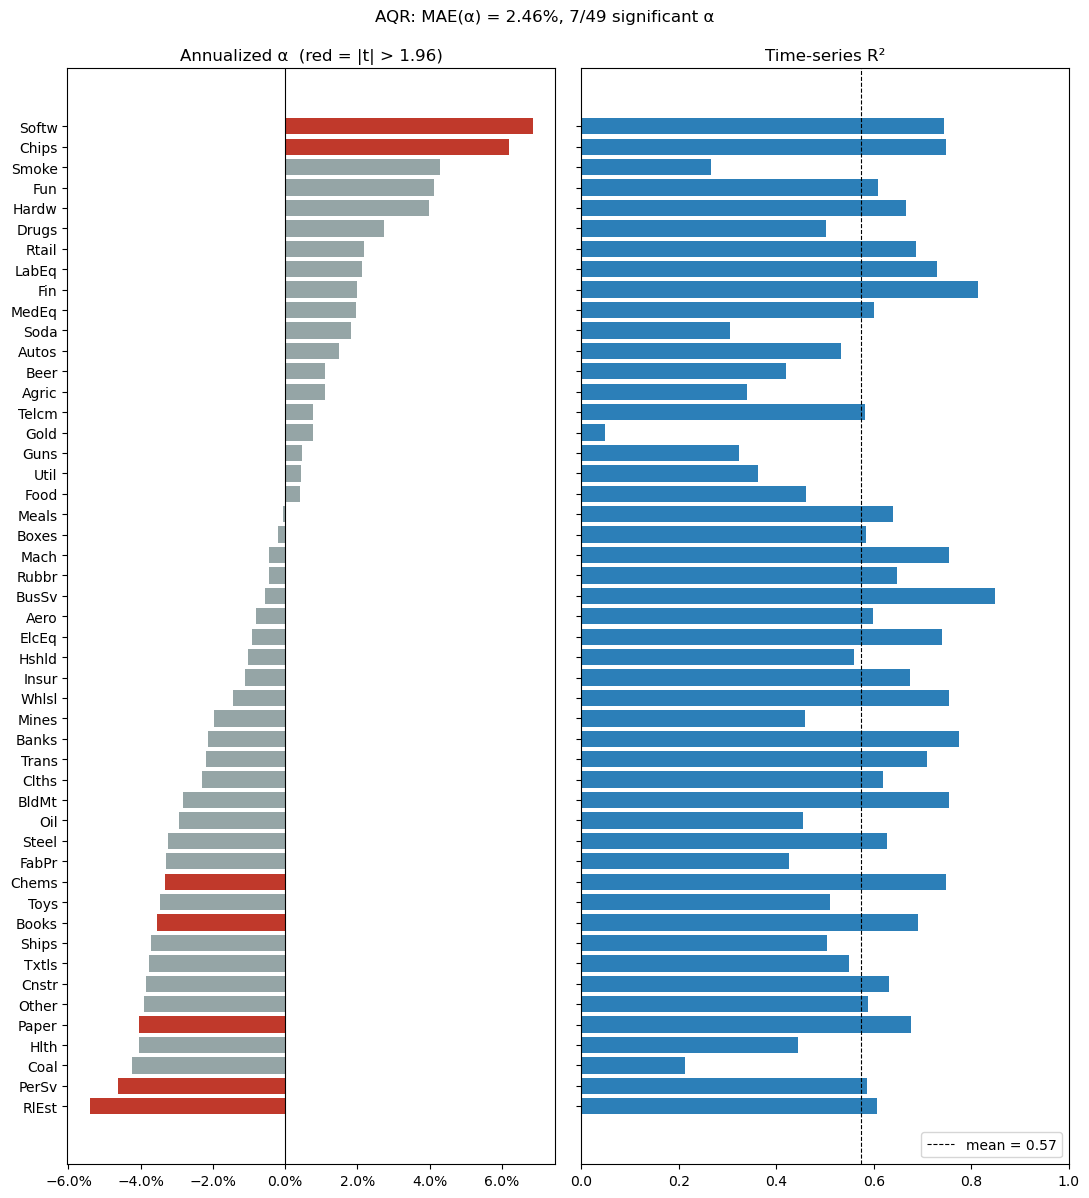

In [60]:
def plot_ts_results(ts, title):
    """Side-by-side bars: alpha (ranked, red if significant) and R², same industry order."""
    d = ts.sort_values("alpha")
    sig = d["t(alpha)"].abs() > 1.96

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 12), sharey=True)
    ax1.barh(d.index, d["alpha"], color=np.where(sig, "#c0392b", "#95a5a6"))
    ax1.axvline(0, color="black", lw=0.8)
    ax1.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax1.set_title("Annualized α  (red = |t| > 1.96)")

    ax2.barh(d.index, d["R2"], color="#2c7fb8")
    ax2.axvline(d["R2"].mean(), color="black", ls="--", lw=0.8, label=f"mean = {d['R2'].mean():.2f}")
    ax2.set_xlim(0, 1)
    ax2.set_title("Time-series R²")
    ax2.legend(loc="lower right")

    fig.suptitle(f"{title}: MAE(α) = {d['alpha'].abs().mean():.2%}, "
                 f"{sig.sum()}/{len(d)} significant α", y=0.995)
    fig.tight_layout()
    plt.show()

plot_ts_results(ts_aqr, "AQR")

## 3.2
Calculate the mean absolute error of the estimated alphas:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n|\tilde{\alpha}^i|$$

- If the pricing model worked, should these alpha estimates be large or small? Why?
- Based on your MAE, does this support the pricing model or not?

In [61]:
# 3.2
mae_aqr = ts_aqr["alpha"].abs().mean()
print(f"AQR MAE(α) = {mae_aqr:.2%} annualized")

AQR MAE(α) = 2.46% annualized


**Answer:**
If the pricing model worked, the alphas should be close to zero, as the expected excess returns would be fully explained by the factor exposures. Any nonzero alpha is a return that the factors fail to explain, and thus a pricing error.

The AQR model's MAE is 2.46% annualized, which is roughly 30% of the market's 8.5% annual premium. Furthermore, 7 of the 49 alphas are significant at the 5% level as seen in the chart above, concentrated in Softw and Chips (positive) and RlEst, PerSv and Paper (negative). This suggests the model does not fully price the industry portfolios.

## 3.3
Test the CAPM, FF3 and FF5.
- Report the MAE for each and compare with the AQR MAE.
- Which model fits best?

In [62]:
# 3.3
ts_results = {name: ts_test(ports, factors, cols) for name, cols in models.items()}

mae_table = pd.DataFrame({
    "MAE(alpha)":          {m: r["alpha"].abs().mean() for m, r in ts_results.items()},
    "# significant alpha": {m: (r["t(alpha)"].abs() > 1.96).sum() for m, r in ts_results.items()},
})
mae_table.style.format({"MAE(alpha)": "{:.2%}"})

,MAE(alpha),# significant alpha
CAPM,2.14%,6
FF3,2.45%,7
FF5,3.15%,16
AQR,2.46%,7


**Answer:**

The CAPM is the model that fits best, with an MAE of 2.14% and only 6 significant non-zero alphas. Surprisingly, the models with more factors do not necessarily fit the data better. Indeed, the FF3/AQR models have a higher MAE (2.45%/2.46%) with 7 significant non-zero alphas, while the model with the most factors (FF5) has an MAE of 3.15% and 16 significant alphas.

## 3.4
Does any particular factor seem especially important or unimportant for pricing? Should Fama and French use the Momentum factor?

**Answer:**

MKT seems to be the most important factor for pricing. The CAPM alone has the lowest MAE (2.14%), which indicates that the additional factors do little to improve the pricing of the industry portfolios.

On the other hand, RMW and CMA seem harmful for pricing industries, as moving from FF3 to FF5 (adding RMW and CMA) raises the MAE from 2.45% to 3.15% and the number of significant alphas from 7 to 16. This is in contrast with the tangency portfolio in 2.4, where they received the largest weights, as the factor that is useful for investing is not necessarily useful for pricing a set of assets.

The AQR model, which drops SMB and CMA and adds UMD (momentum), has a lower MAE than FF5 (2.46% vs 3.15%). This suggests Fama and French could benefit from including UMD, but the comparison does not isolate just UMD's contribution since the models also differ in SMB and CMA. In any case, neither model beats the CAPM on these 49 industry portfolios.

## 3.5
Report the average (across $n$) time-series $R^2$ for each of the four models.
- Do these models lead to high time-series $R^2$? Would these factors be good for a Linear Factor Decomposition of the assets?

In [63]:
avg_r2 = {}
for m in ts_results:
    avg_r2[m] = ts_results[m]["R2"].mean()

pd.Series(avg_r2, name="Avg time-series R²").round(3)


CAPM    0.524
FF3     0.570
FF5     0.594
AQR     0.574
Name: Avg time-series R², dtype: float64

**Answer:**

Across the models, R² is moderate, between 52% and 59%. The CAPM alone explains 52.4% of the return variation, indicating that the market does most of the work out of all factors. Adding 2 and 4 more factors (FF3 and FF5) adds only 5 and 7 percentage points of explanatory power.

For a linear factor decomposition, explaining around half of the variance is not good enough. Half of the variance can't be replicated or explained with these factors in most industries, and some industry portfolio returns are almost entirely unexplained (Gold 0.05, Coal 0.21).

However, R² and pricing are different things. FF5 has the highest R² (0.59) but the worst MAE (3.15%), while the CAPM has the lowest R² and the best MAE. R² will always rise when adding additional factors, but that does not necessarily improve the accuracy of the pricing model.

## 3.6
Re-test all four models using cross-sectional regressions **with an intercept**.
- Report the time-series factor premia (sample averages) and compare to the cross-sectionally estimated premia. Do they differ substantially?
- Report the MAE of the cross-sectional residuals for each model. How do they compare to the MAE of the time-series alphas?

In [64]:
mean_rets = ports.mean() * 12                     

cs_results = {}
for m in models:
    cols  = models[m]
    betas = ts_results[m][[f"beta_{c}" for c in cols]]
    betas.columns = cols
    X = sm.add_constant(betas)
    cs_results[m] = sm.OLS(mean_rets, X).fit()   

premia = {}
for m in cs_results:
    premia[m] = cs_results[m].params
premia["Time-series (sample mean)"] = factors.mean() * 12

premia = pd.DataFrame(premia).T[["const", "MKT", "SMB", "HML", "RMW", "CMA", "UMD"]]
premia.style.format("{:.2%}", na_rep="—")

,const,MKT,SMB,HML,RMW,CMA,UMD
CAPM,8.69%,0.21%,—,—,—,—,—
FF3,6.24%,3.76%,-4.47%,-1.99%,—,—,—
FF5,6.00%,3.84%,-4.70%,-2.58%,2.31%,-2.43%,—
AQR,7.58%,1.44%,—,-3.26%,2.13%,—,0.19%
Time-series (sample mean),—,8.49%,0.54%,2.65%,4.51%,2.77%,6.18%


**Answer:**

The cross-sectional premia are substantially different from the time-series premia. The market premium is 0.21%–3.84% cross-sectionally versus 8.49% in the time series.
Furthermore, SMB, HML and CMA all receive negative cross-sectional premia despite positive sample means, while those for RMW and UMD are decreased substantially or even completely wiped out (RMW c. 2.2% vs 4.51%; UMD 0.19% vs 6.18%). Moreover, the intercepts are large (6.00%–8.69%), whereas they should be zero if the models held.

In [65]:
mae_compare = {}
for m in models:
    mae_compare[m] = {
        "TS MAE(α)":        ts_results[m]["alpha"].abs().mean(),
        "CS MAE(residual)": cs_results[m].resid.abs().mean(),
        "CS R²":            cs_results[m].rsquared,
    }

mae_compare = pd.DataFrame(mae_compare).T
mae_compare.style.format({"TS MAE(α)": "{:.2%}", "CS MAE(residual)": "{:.2%}", "CS R²": "{:.2f}"})

,TS MAE(α),CS MAE(residual),CS R²
CAPM,2.14%,1.55%,0.00
FF3,2.45%,1.20%,0.38
FF5,3.15%,1.19%,0.42
AQR,2.46%,1.38%,0.21


**Answer continued:**

The cross-sectional MAEs (1.19%–1.55%) are smaller than the time-series MAEs (2.14%–3.15%) for every model. However, this is expected as the time-series test forces the premia to equal the factor sample means, while the cross-sectional regression chooses the premia (and an intercept) that best fit the 49 average returns. Opposite to the TS MAE, the FF5 is the best fit cross-sectionally and the worst in the time series, while the CAPM is the reverse (with a cross-sectional R² of 0.00).


## Acknowledgement: 

We used Claude (Opus 5.5) to help with writting the code and setting up the notebook and submission structure.   